# FEM Laboratory · 01
## From weak forms to assembly and convergence

Experiments for Chapter **1.1**, sections 1–6 and 9. This notebook is self-contained:
run it in a fresh kernel; no previous notebook or saved data is required.

[Chapter guide](README.md) · [Setup and outputs](NOTEBOOK_README.md) · [Practical exercises](exercises/FEM_Foundations_Exercises.ipynb)

Python 3.11+; NumPy/SciPy, CPU / float64. Select **Restart Kernel and Run All Cells**.
We use a small one-dimensional P1 implementation to expose every matrix entry.
This is a finite element method implemented in NumPy/SciPy; it does not use FEniCS.

**Notation:** $u$ is the exact state, $u_h$ the continuous piecewise-linear state,
$K$ the stiffness matrix, $M$ the consistent mass matrix and $b$ the load vector.


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Matplotlib is building the font cache; this may take a moment.


Python 3.13.9 · NumPy 2.4.2 · SciPy 1.17.0
CPU / float64 / deterministic quadrature / seed 7


## 1 · From a PDE to an energy

For $-u''=f$ on $(0,1)$ with $u(0)=u(1)=0$, integration by parts gives
$a(u,v)=\int u'v'=\int fv=\ell(v)$ for every $v\in H_0^1(0,1)$.
The energy is $E(v)=\tfrac12a(v,v)-\ell(v)$. Coercivity on $H_0^1$ makes its minimizer unique.

Choose $u(x)=\sin(\pi x)$, hence $f=\pi^2\sin(\pi x)$.
On an interval of length $h$, the affine reference map gives
$K_e=h^{-1}\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$ and
$M_e=\tfrac h6\begin{pmatrix}2&1\\1&2\end{pmatrix}$.
Five-point Gauss quadrature assembles the nonpolynomial load.


In [2]:
# Shared mathematical scaffold, repeated here so this notebook runs independently.
def assemble_p1(nodes, forcing=lambda x: np.zeros_like(x), diffusion=lambda x: np.ones_like(x)):
    """P1 stiffness, consistent mass and load; five-point Gauss quadrature."""
    nodes = np.asarray(nodes, dtype=np.float64)
    assert np.all(np.diff(nodes) > 0)
    z, w = np.polynomial.legendre.leggauss(5)
    phi = np.column_stack(((1-z)/2, (1+z)/2))
    rows, cols, stiffness, mass = [], [], [], []
    load = np.zeros(len(nodes))
    for e, h in enumerate(np.diff(nodes)):
        q = nodes[e] + (z+1)*h/2
        ke = np.array([[1., -1.], [-1., 1.]]) * np.dot(w, diffusion(q))/(2*h)
        me = h/6 * np.array([[2., 1.], [1., 2.]])
        fe = h/2 * (phi.T @ (w*forcing(q)))
        for i in range(2):
            load[e+i] += fe[i]
            for j in range(2):
                rows.append(e+i); cols.append(e+j)
                stiffness.append(ke[i,j]); mass.append(me[i,j])
    shape = (len(nodes), len(nodes))
    return (sparse.coo_matrix((stiffness, (rows, cols)), shape=shape).tocsr(),
            sparse.coo_matrix((mass, (rows, cols)), shape=shape).tocsr(), load)

def solve_dirichlet(K, load, values=(0., 0.)):
    uh = np.zeros(K.shape[0]); uh[[0,-1]] = values
    uh[1:-1] = spsolve(K[1:-1, 1:-1], load[1:-1] - (K @ uh)[1:-1])
    return uh

def errors_p1(nodes, uh, exact, derivative):
    z, w = np.polynomial.legendre.leggauss(8)
    h = np.diff(nodes)
    q = nodes[:-1,None] + h[:,None]*(z[None,:]+1)/2
    discrete = uh[:-1,None]*(1-z)/2 + uh[1:,None]*(1+z)/2
    gradient = np.diff(uh)/h
    L2_sq = np.sum(h[:,None]/2*w*(discrete-exact(q))**2)
    H1_sq = np.sum(h[:,None]/2*w*(gradient[:,None]-derivative(q))**2)
    return np.sqrt([L2_sq, H1_sq])


Interior degrees of freedom: 15
First 4 x 4 block of K:
 [[ 16. -16.   0.   0.]
 [-16.  32. -16.   0.]
 [  0. -16.  32. -16.]
 [  0.   0. -16.  32.]]


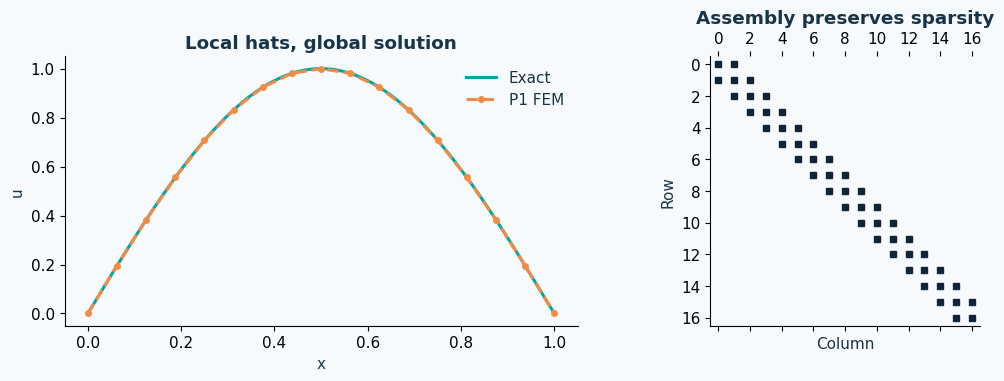

In [3]:
exact = lambda x: np.sin(np.pi*x)
derivative = lambda x: np.pi*np.cos(np.pi*x)
forcing = lambda x: np.pi**2*exact(x)
nodes = np.linspace(0, 1, 17)
K, M, b = assemble_p1(nodes, forcing)
uh = solve_dirichlet(K, b)
assert np.max(np.abs((K @ uh-b)[1:-1])) < 1e-11
assert np.allclose(K.toarray(), K.toarray().T)
print("Interior degrees of freedom:", len(nodes)-2)
print("First 4 x 4 block of K:\n", K[:4,:4].toarray())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
xf = np.linspace(0, 1, 500)
axs[0].plot(xf, exact(xf), label="Exact")
axs[0].plot(nodes, uh, "o--", ms=4, label="P1 FEM")
axs[0].set(xlabel="x", ylabel="u", title="Local hats, global solution"); axs[0].legend()
axs[1].spy(K, markersize=5, color=palette["navy"])
axs[1].set(title="Assembly preserves sparsity", xlabel="Column", ylabel="Row")
plt.show()


## 2 · Galerkin orthogonality and best energy approximation

The interior equations say $a(u-u_h,v_h)=0$. A random discrete perturbation
$v_h$ therefore changes energy by exactly $\tfrac12v_h^T K v_h$.
The residual tests the linear solve; it does **not** measure the discretization error.


In [4]:
perturbation = rng.normal(size=len(nodes)); perturbation[[0,-1]] = 0
energy = lambda coefficients: .5*coefficients @ (K @ coefficients)-b @ coefficients
energy_change = energy(uh+perturbation)-energy(uh)
predicted_change = .5*perturbation @ (K @ perturbation)
assert np.isclose(energy_change, predicted_change, rtol=1e-12)
print(f"Energy increase: {energy_change:.6f}; quadratic prediction: {predicted_change:.6f}")
print("L2 and H1 seminorm errors:", errors_p1(nodes, uh, exact, derivative))
print("Discrete orthogonality residual:", abs(perturbation @ (K @ uh-b)))


Energy increase: 92.818294; quadratic prediction: 92.818294
L2 and H1 seminorm errors: [0.0025 0.1258]
Discrete orthogonality residual: 1.950123223741831e-15


## 3 · Convergence is a sequence of experiments

For smooth $u$, P1 elements should give $\|u-u_h\|_{L^2}=O(h^2)$ and
$|u-u_h|_{H^1}=O(h)$. Compute errors by independent, higher-order quadrature,
not by comparing only nodal values: in this one-dimensional constant-coefficient
problem the FEM nodal values are almost exact while the field between nodes is not.


     h          L2 error      H1 seminorm
 1.25000e-01   9.92092e-03   2.51182e-01
 6.25000e-02   2.48650e-03   1.25833e-01
 3.12500e-02   6.22018e-04   6.29469e-02
 1.56250e-02   1.55529e-04   3.14772e-02
 7.81250e-03   3.88838e-05   1.57391e-02
Last observed rates [L2, H1]: [1.9999 1.    ]


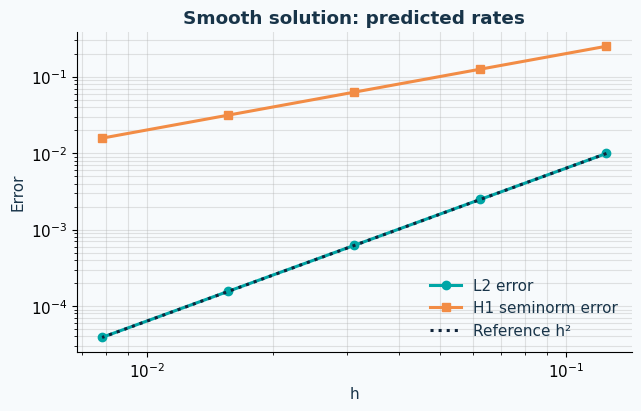

In [5]:
levels = [8, 16, 32, 64, 128]
records = []
for n in levels:
    x = np.linspace(0, 1, n+1)
    Kn, _, bn = assemble_p1(x, forcing)
    un = solve_dirichlet(Kn, bn)
    records.append((1/n, *errors_p1(x, un, exact, derivative)))
records = np.array(records)
rates = np.log(records[:-1,1:]/records[1:,1:])/np.log(2)
print("     h          L2 error      H1 seminorm")
for row in records: print("  ".join(f"{v:12.5e}" for v in row))
print("Last observed rates [L2, H1]:", rates[-1])
assert 1.95 < rates[-1,0] < 2.05 and .95 < rates[-1,1] < 1.05
fig, ax = plt.subplots(figsize=(6.3, 4), layout="constrained")
ax.loglog(records[:,0], records[:,1], "o-", label="L2 error")
ax.loglog(records[:,0], records[:,2], "s-", label="H1 seminorm error")
ax.loglog(records[:,0], records[0,1]*(records[:,0]/records[0,0])**2, ":", label="Reference h²")
ax.set(xlabel="h", ylabel="Error", title="Smooth solution: predicted rates")
ax.grid(which="both"); ax.legend(); plt.show()


## 4 · Nonzero boundary data require a lifted right-hand side

Now take $u(x)=1+2x+\sin(\pi x)$. The forcing is unchanged but the interior
right-hand side becomes $b_I-K_{IB}g_B$. Zeroing boundary columns without adjusting the interior load is a common
implementation error. Keeping the interior columns and replacing only boundary
rows is also valid, although it destroys matrix symmetry.


In [6]:
lifted_exact = lambda x: 1+2*x+np.sin(np.pi*x)
lifted_derivative = lambda x: 2+np.pi*np.cos(np.pi*x)
lifted = solve_dirichlet(K, b, values=(1., 3.))
assert np.allclose(lifted, uh+1+2*nodes)
print("Boundary values:", lifted[[0,-1]])
print("Lifted L2 / H1 errors:", errors_p1(nodes, lifted, lifted_exact, lifted_derivative))


Boundary values: [1. 3.]
Lifted L2 / H1 errors: [0.0025 0.1258]


## Try next

Replace the diffusion coefficient by $a(x)=1+x$ and derive the manufactured
forcing $f=-(au')'$ before changing the code. Compare a uniform mesh with a graded
mesh at equal degrees of freedom. Explain why a small algebraic residual alone
cannot certify either the PDE model or the mesh resolution.

**Checks before trusting a simulation:** boundary values, matrix symmetry and positive
definiteness after constraints, residual on free degrees of freedom, quadrature accuracy,
independent error integration, and rates under refinement.
